In [1]:

!pip -q install huggingface_hub

from huggingface_hub import hf_hub_download
import pandas as pd
import os

path = hf_hub_download(
    repo_id="xpertsystems/mfg005-sample",
    filename="mfg005_synthetic_line_performance.csv",
    repo_type="dataset"
)

df_b = pd.read_csv(path)

print("Dataset loaded!")
print("Shape:", df_b.shape)

display(df_b.head())


mfg005_synthetic_line_performance.csv:   0%|          | 0.00/2.34M [00:00<?, ?B/s]

Dataset loaded!
Shape: (3000, 118)


,line_id,plant_id,work_center_id,shift_id,shift_date,shift_number,shift_duration_minutes,product_id,product_family,production_order_id,...,direct_labour_cost_usd,overhead_cost_usd,material_cost_per_unit_usd,scrap_cost_usd,rework_cost_usd,downtime_cost_per_minute_usd,total_downtime_cost_usd,cost_of_poor_quality_usd,value_added_ratio_pct,production_cost_per_unit_usd
0,MFG-LINE-PLT-004-06,PLT-004,WC-037,SHF-PLT-004-20210729-1,2021-07-29,1,475.1,PRD-2021-SKU-05702,industrial_machinery,WO-2021-98019,...,2262.01,5082.56,88.54,0.0,22.14,100,0.0,22.14,32.8,120.3054
1,MFG-LINE-PLT-005-05,PLT-005,WC-048,SHF-PLT-005-20200508-1,2020-05-08,1,473.0,PRD-2020-SKU-05736,automotive_body,WO-2020-36066,...,8404.33,16045.01,30.59,0.0,7.65,200,22700.0,4547.65,40.8,120.9218
2,MFG-LINE-PLT-005-01,PLT-005,WC-039,SHF-PLT-005-20221016-3,2022-10-16,3,450.2,PRD-2022-SKU-04660,automotive_body,WO-2022-67019,...,683.77,1120.42,28.64,0.0,7.16,200,26220.0,5251.16,29.2,33.3516
3,MFG-LINE-PLT-007-02,PLT-007,WC-015,SHF-PLT-007-20230816-2,2023-08-16,2,440.3,PRD-2023-SKU-01042,industrial_machinery,WO-2023-12387,...,7153.94,17517.75,29.60,0.0,7.40,100,1460.0,299.40,74.2,323.6630
4,MFG-LINE-PLT-001-02,PLT-001,WC-042,SHF-PLT-001-20241024-3,2024-10-24,3,447.9,PRD-2024-SKU-02680,pharmaceutical,WO-2024-99757,...,5792.34,12584.63,29.25,0.0,7.31,300,19740.0,3955.31,74.9,84.8579


In [2]:

print("Columns:")
for col in df_b.columns:
    print(col)

print("\nDataset information:")
df_b.info()

print("\nMissing values:")
print(df_b.isnull().sum())


Columns:
line_id
plant_id
work_center_id
shift_id
shift_date
shift_number
shift_duration_minutes
product_id
product_family
production_order_id
line_type
automation_level
number_of_stations
line_configuration
plant_location
industry_sector
takt_time_seconds
designed_cycle_time_seconds
actual_cycle_time_avg_seconds
actual_cycle_time_std_seconds
actual_cycle_time_min_seconds
actual_cycle_time_max_seconds
cycle_time_percentile_p50
cycle_time_percentile_p95
cycle_time_cov
bottleneck_station_id
bottleneck_cycle_time_seconds
bottleneck_utilisation_pct
secondary_bottleneck_station_id
cycle_time_loss_seconds
planned_production_quantity
actual_production_quantity
good_units_produced
defective_units_produced
scrap_units
rework_units
throughput_rate_actual_uph
throughput_rate_design_uph
throughput_rate_ratio
rolled_throughput_yield_pct
total_parts_processed
wip_queue_avg_units
wip_queue_max_units
output_variance_pct
units_per_operator_hour
planned_production_time_minutes
available_time_minutes
oee

In [3]:

print(df_b.columns.tolist())



['line_id', 'plant_id', 'work_center_id', 'shift_id', 'shift_date', 'shift_number', 'shift_duration_minutes', 'product_id', 'product_family', 'production_order_id', 'line_type', 'automation_level', 'number_of_stations', 'line_configuration', 'plant_location', 'industry_sector', 'takt_time_seconds', 'designed_cycle_time_seconds', 'actual_cycle_time_avg_seconds', 'actual_cycle_time_std_seconds', 'actual_cycle_time_min_seconds', 'actual_cycle_time_max_seconds', 'cycle_time_percentile_p50', 'cycle_time_percentile_p95', 'cycle_time_cov', 'bottleneck_station_id', 'bottleneck_cycle_time_seconds', 'bottleneck_utilisation_pct', 'secondary_bottleneck_station_id', 'cycle_time_loss_seconds', 'planned_production_quantity', 'actual_production_quantity', 'good_units_produced', 'defective_units_produced', 'scrap_units', 'rework_units', 'throughput_rate_actual_uph', 'throughput_rate_design_uph', 'throughput_rate_ratio', 'rolled_throughput_yield_pct', 'total_parts_processed', 'wip_queue_avg_units', 'wip

In [4]:

print(df_b["industry_sector"].value_counts())

auto = df_b[
    df_b["industry_sector"].astype(str).str.lower()
    == "automotive"
].copy()

print("Automotive records:", len(auto))
display(auto.head())


industry_sector
industrial     1131
electronics     733
automotive      660
medical         165
food_bev        156
pharma          155
Name: count, dtype: int64
Automotive records: 660


,line_id,plant_id,work_center_id,shift_id,shift_date,shift_number,shift_duration_minutes,product_id,product_family,production_order_id,...,direct_labour_cost_usd,overhead_cost_usd,material_cost_per_unit_usd,scrap_cost_usd,rework_cost_usd,downtime_cost_per_minute_usd,total_downtime_cost_usd,cost_of_poor_quality_usd,value_added_ratio_pct,production_cost_per_unit_usd
1,MFG-LINE-PLT-005-05,PLT-005,WC-048,SHF-PLT-005-20200508-1,2020-05-08,1,473.0,PRD-2020-SKU-05736,automotive_body,WO-2020-36066,...,8404.33,16045.01,30.59,0.0,7.65,200,22700.0,4547.65,40.8,120.9218
2,MFG-LINE-PLT-005-01,PLT-005,WC-039,SHF-PLT-005-20221016-3,2022-10-16,3,450.2,PRD-2022-SKU-04660,automotive_body,WO-2022-67019,...,683.77,1120.42,28.64,0.0,7.16,200,26220.0,5251.16,29.2,33.3516
6,MFG-LINE-PLT-005-05,PLT-005,WC-003,SHF-PLT-005-20240625-3,2024-06-25,3,435.3,PRD-2024-SKU-02707,automotive_body,WO-2024-01817,...,6166.39,7796.90,33.88,0.0,8.47,200,5120.0,1032.47,27.5,79.6224
7,MFG-LINE-PLT-005-04,PLT-005,WC-017,SHF-PLT-005-20240327-1,2024-03-27,1,456.6,PRD-2024-SKU-07919,automotive_body,WO-2024-13111,...,3400.15,6198.53,57.40,0.0,14.35,200,9700.0,1954.35,71.8,78.1658
16,MFG-LINE-PLT-005-03,PLT-005,WC-007,SHF-PLT-005-20231218-1,2023-12-18,1,478.1,PRD-2023-SKU-06623,automotive_body,WO-2023-94883,...,970.36,1662.49,53.07,0.0,13.27,200,9480.0,1909.27,56.3,59.5421


In [5]:

print(auto.columns.tolist())

for col in auto.columns:
    if "bottleneck" in col.lower():
        print("\n", col)
        print(auto[col].value_counts(dropna=False).head(20))


['line_id', 'plant_id', 'work_center_id', 'shift_id', 'shift_date', 'shift_number', 'shift_duration_minutes', 'product_id', 'product_family', 'production_order_id', 'line_type', 'automation_level', 'number_of_stations', 'line_configuration', 'plant_location', 'industry_sector', 'takt_time_seconds', 'designed_cycle_time_seconds', 'actual_cycle_time_avg_seconds', 'actual_cycle_time_std_seconds', 'actual_cycle_time_min_seconds', 'actual_cycle_time_max_seconds', 'cycle_time_percentile_p50', 'cycle_time_percentile_p95', 'cycle_time_cov', 'bottleneck_station_id', 'bottleneck_cycle_time_seconds', 'bottleneck_utilisation_pct', 'secondary_bottleneck_station_id', 'cycle_time_loss_seconds', 'planned_production_quantity', 'actual_production_quantity', 'good_units_produced', 'defective_units_produced', 'scrap_units', 'rework_units', 'throughput_rate_actual_uph', 'throughput_rate_design_uph', 'throughput_rate_ratio', 'rolled_throughput_yield_pct', 'total_parts_processed', 'wip_queue_avg_units', 'wip

In [6]:

# Inspect possible date and shift columns
for col in auto.columns:
    if any(word in col.lower() for word in
           ["date", "shift", "line", "station"]):
        print("\n", col)
        print(auto[col].head(10).tolist())



 line_id
['MFG-LINE-PLT-005-05', 'MFG-LINE-PLT-005-01', 'MFG-LINE-PLT-005-05', 'MFG-LINE-PLT-005-04', 'MFG-LINE-PLT-005-03', 'MFG-LINE-PLT-009-01', 'MFG-LINE-PLT-005-05', 'MFG-LINE-PLT-005-03', 'MFG-LINE-PLT-009-02', 'MFG-LINE-PLT-005-04']

 shift_id
['SHF-PLT-005-20200508-1', 'SHF-PLT-005-20221016-3', 'SHF-PLT-005-20240625-3', 'SHF-PLT-005-20240327-1', 'SHF-PLT-005-20231218-1', 'SHF-PLT-009-20210811-2', 'SHF-PLT-005-20200417-2', 'SHF-PLT-005-20210705-1', 'SHF-PLT-009-20231208-1', 'SHF-PLT-005-20230923-1']

 shift_date
['2020-05-08', '2022-10-16', '2024-06-25', '2024-03-27', '2023-12-18', '2021-08-11', '2020-04-17', '2021-07-05', '2023-12-08', '2023-09-23']

 shift_number
[1, 3, 3, 1, 1, 2, 2, 1, 1, 1]

 shift_duration_minutes
[473.0, 450.2, 435.3, 456.6, 478.1, 470.0, 455.2, 465.9, 425.2, 452.9]

 line_type
['continuous_process', 'fabrication', 'continuous_process', 'packaging_line', 'chemical_process', 'batch_process', 'continuous_process', 'chemical_process', 'hybrid', 'packaging_l

In [7]:

# Display all column names with their index

for i, col in enumerate(df_b.columns):
    print(i, ":", col)


0 : line_id
1 : plant_id
2 : work_center_id
3 : shift_id
4 : shift_date
5 : shift_number
6 : shift_duration_minutes
7 : product_id
8 : product_family
9 : production_order_id
10 : line_type
11 : automation_level
12 : number_of_stations
13 : line_configuration
14 : plant_location
15 : industry_sector
16 : takt_time_seconds
17 : designed_cycle_time_seconds
18 : actual_cycle_time_avg_seconds
19 : actual_cycle_time_std_seconds
20 : actual_cycle_time_min_seconds
21 : actual_cycle_time_max_seconds
22 : cycle_time_percentile_p50
23 : cycle_time_percentile_p95
24 : cycle_time_cov
25 : bottleneck_station_id
26 : bottleneck_cycle_time_seconds
27 : bottleneck_utilisation_pct
28 : secondary_bottleneck_station_id
29 : cycle_time_loss_seconds
30 : planned_production_quantity
31 : actual_production_quantity
32 : good_units_produced
33 : defective_units_produced
34 : scrap_units
35 : rework_units
36 : throughput_rate_actual_uph
37 : throughput_rate_design_uph
38 : throughput_rate_ratio
39 : rolled_thro

In [8]:

print("Dataset shape:", df_b.shape)

print("\nData types:")
print(df_b.dtypes)

print("\nMissing values:")
print(df_b.isnull().sum())

print("\nFirst 10 records:")
display(df_b.head(10))


Dataset shape: (3000, 118)

Data types:
line_id                          object
plant_id                         object
work_center_id                   object
shift_id                         object
shift_date                       object
                                 ...   
downtime_cost_per_minute_usd      int64
total_downtime_cost_usd         float64
cost_of_poor_quality_usd        float64
value_added_ratio_pct           float64
production_cost_per_unit_usd    float64
Length: 118, dtype: object

Missing values:
line_id                         0
plant_id                        0
work_center_id                  0
shift_id                        0
shift_date                      0
                               ..
downtime_cost_per_minute_usd    0
total_downtime_cost_usd         0
cost_of_poor_quality_usd        0
value_added_ratio_pct           0
production_cost_per_unit_usd    0
Length: 118, dtype: int64

First 10 records:


,line_id,plant_id,work_center_id,shift_id,shift_date,shift_number,shift_duration_minutes,product_id,product_family,production_order_id,...,direct_labour_cost_usd,overhead_cost_usd,material_cost_per_unit_usd,scrap_cost_usd,rework_cost_usd,downtime_cost_per_minute_usd,total_downtime_cost_usd,cost_of_poor_quality_usd,value_added_ratio_pct,production_cost_per_unit_usd
0,MFG-LINE-PLT-004-06,PLT-004,WC-037,SHF-PLT-004-20210729-1,2021-07-29,1,475.1,PRD-2021-SKU-05702,industrial_machinery,WO-2021-98019,...,2262.01,5082.56,88.54,0.00,22.14,100,0.0,22.14,32.8,120.3054
1,MFG-LINE-PLT-005-05,PLT-005,WC-048,SHF-PLT-005-20200508-1,2020-05-08,1,473.0,PRD-2020-SKU-05736,automotive_body,WO-2020-36066,...,8404.33,16045.01,30.59,0.00,7.65,200,22700.0,4547.65,40.8,120.9218
2,MFG-LINE-PLT-005-01,PLT-005,WC-039,SHF-PLT-005-20221016-3,2022-10-16,3,450.2,PRD-2022-SKU-04660,automotive_body,WO-2022-67019,...,683.77,1120.42,28.64,0.00,7.16,200,26220.0,5251.16,29.2,33.3516
3,MFG-LINE-PLT-007-02,PLT-007,WC-015,SHF-PLT-007-20230816-2,2023-08-16,2,440.3,PRD-2023-SKU-01042,industrial_machinery,WO-2023-12387,...,7153.94,17517.75,29.60,0.00,7.40,100,1460.0,299.40,74.2,323.6630
4,MFG-LINE-PLT-001-02,PLT-001,WC-042,SHF-PLT-001-20241024-3,2024-10-24,3,447.9,PRD-2024-SKU-02680,pharmaceutical,WO-2024-99757,...,5792.34,12584.63,29.25,0.00,7.31,300,19740.0,3955.31,74.9,84.8579
5,MFG-LINE-PLT-006-02,PLT-006,WC-027,SHF-PLT-006-20200420-3,2020-04-20,3,449.8,PRD-2020-SKU-03525,food_beverage,WO-2020-85336,...,173.93,322.51,8.98,17.96,8.98,80,11512.0,2329.34,37.1,9.2618
6,MFG-LINE-PLT-005-05,PLT-005,WC-003,SHF-PLT-005-20240625-3,2024-06-25,3,435.3,PRD-2024-SKU-02707,automotive_body,WO-2024-01817,...,6166.39,7796.90,33.88,0.00,8.47,200,5120.0,1032.47,27.5,79.6224
7,MFG-LINE-PLT-005-04,PLT-005,WC-017,SHF-PLT-005-20240327-1,2024-03-27,1,456.6,PRD-2024-SKU-07919,automotive_body,WO-2024-13111,...,3400.15,6198.53,57.40,0.00,14.35,200,9700.0,1954.35,71.8,78.1658
8,MFG-LINE-PLT-002-04,PLT-002,WC-017,SHF-PLT-002-20200326-3,2020-03-26,3,434.6,PRD-2020-SKU-07478,electronics_pcb,WO-2020-24841,...,1134.16,1380.20,14.64,14.64,10.98,150,13815.0,2788.62,60.5,17.8764
9,MFG-LINE-PLT-003-03,PLT-003,WC-014,SHF-PLT-003-20200307-3,2020-03-07,3,466.6,PRD-2020-SKU-07716,electronics_pcb,WO-2020-74961,...,795.80,876.41,15.13,0.00,3.78,150,22395.0,4482.78,58.9,16.3067


In [9]:

keywords = [
    "industry",
    "line",
    "station",
    "bottleneck",
    "cycle",
    "takt",
    "queue",
    "throughput",
    "downtime",
    "availability",
    "oee",
    "shift",
    "date"
]

for col in df_b.columns:
    if any(word in col.lower() for word in keywords):
        print("\nColumn:", col)
        print("Sample values:")
        print(df_b[col].head(5).tolist())



Column: line_id
Sample values:
['MFG-LINE-PLT-004-06', 'MFG-LINE-PLT-005-05', 'MFG-LINE-PLT-005-01', 'MFG-LINE-PLT-007-02', 'MFG-LINE-PLT-001-02']

Column: shift_id
Sample values:
['SHF-PLT-004-20210729-1', 'SHF-PLT-005-20200508-1', 'SHF-PLT-005-20221016-3', 'SHF-PLT-007-20230816-2', 'SHF-PLT-001-20241024-3']

Column: shift_date
Sample values:
['2021-07-29', '2020-05-08', '2022-10-16', '2023-08-16', '2024-10-24']

Column: shift_number
Sample values:
[1, 1, 3, 2, 3]

Column: shift_duration_minutes
Sample values:
[475.1, 473.0, 450.2, 440.3, 447.9]

Column: line_type
Sample values:
['chemical_process', 'continuous_process', 'fabrication', 'hybrid', 'fabrication']

Column: number_of_stations
Sample values:
[3, 3, 4, 2, 5]

Column: line_configuration
Sample values:
['job_shop', 'serial', 'transfer_line', 'parallel', 'transfer_line']

Column: industry_sector
Sample values:
['industrial', 'automotive', 'automotive', 'industrial', 'pharma']

Column: takt_time_seconds
Sample values:
[126.5, 5

In [10]:

print(df_b["industry_sector"].value_counts(dropna=False))



industry_sector
industrial     1131
electronics     733
automotive      660
medical         165
food_bev        156
pharma          155
Name: count, dtype: int64


In [11]:

auto = df_b[
    df_b["industry_sector"].astype(str).str.lower()
    == "automotive"
].copy()

print("Automotive records:", len(auto))
display(auto.head())


Automotive records: 660


,line_id,plant_id,work_center_id,shift_id,shift_date,shift_number,shift_duration_minutes,product_id,product_family,production_order_id,...,direct_labour_cost_usd,overhead_cost_usd,material_cost_per_unit_usd,scrap_cost_usd,rework_cost_usd,downtime_cost_per_minute_usd,total_downtime_cost_usd,cost_of_poor_quality_usd,value_added_ratio_pct,production_cost_per_unit_usd
1,MFG-LINE-PLT-005-05,PLT-005,WC-048,SHF-PLT-005-20200508-1,2020-05-08,1,473.0,PRD-2020-SKU-05736,automotive_body,WO-2020-36066,...,8404.33,16045.01,30.59,0.0,7.65,200,22700.0,4547.65,40.8,120.9218
2,MFG-LINE-PLT-005-01,PLT-005,WC-039,SHF-PLT-005-20221016-3,2022-10-16,3,450.2,PRD-2022-SKU-04660,automotive_body,WO-2022-67019,...,683.77,1120.42,28.64,0.0,7.16,200,26220.0,5251.16,29.2,33.3516
6,MFG-LINE-PLT-005-05,PLT-005,WC-003,SHF-PLT-005-20240625-3,2024-06-25,3,435.3,PRD-2024-SKU-02707,automotive_body,WO-2024-01817,...,6166.39,7796.90,33.88,0.0,8.47,200,5120.0,1032.47,27.5,79.6224
7,MFG-LINE-PLT-005-04,PLT-005,WC-017,SHF-PLT-005-20240327-1,2024-03-27,1,456.6,PRD-2024-SKU-07919,automotive_body,WO-2024-13111,...,3400.15,6198.53,57.40,0.0,14.35,200,9700.0,1954.35,71.8,78.1658
16,MFG-LINE-PLT-005-03,PLT-005,WC-007,SHF-PLT-005-20231218-1,2023-12-18,1,478.1,PRD-2023-SKU-06623,automotive_body,WO-2023-94883,...,970.36,1662.49,53.07,0.0,13.27,200,9480.0,1909.27,56.3,59.5421


In [12]:

bottleneck_columns = [
    col for col in auto.columns
    if "bottleneck" in col.lower()
]

print("Bottleneck-related columns:")
print(bottleneck_columns)

for col in bottleneck_columns:
    print("\n", col)
    print(auto[col].value_counts(dropna=False).head(20))


Bottleneck-related columns:
['bottleneck_station_id', 'bottleneck_cycle_time_seconds', 'bottleneck_utilisation_pct', 'secondary_bottleneck_station_id']

 bottleneck_station_id
bottleneck_station_id
WC-001    168
WC-002    164
WC-003    131
WC-004     69
WC-005     33
WC-006     31
WC-007     21
WC-010     16
WC-009     16
WC-008     11
Name: count, dtype: int64

 bottleneck_cycle_time_seconds
bottleneck_cycle_time_seconds
65.31    3
84.24    2
54.87    2
71.62    2
67.32    2
86.54    2
53.94    2
60.93    2
77.56    2
73.32    2
87.26    2
59.92    2
56.21    2
59.85    2
73.65    2
82.33    2
54.39    2
67.45    2
70.22    2
40.77    2
Name: count, dtype: int64

 bottleneck_utilisation_pct
bottleneck_utilisation_pct
99.90    71
92.11     4
96.57     4
93.37     3
93.43     3
91.62     3
95.24     3
92.69     3
95.59     3
94.41     3
92.79     3
92.37     3
91.91     3
92.85     3
93.87     3
95.83     3
92.92     3
94.52     3
91.99     3
93.20     3
Name: count, dtype: int64

 seco

Selected input features:
['line_id', 'plant_id', 'shift_number', 'shift_duration_minutes', 'line_type', 'automation_level', 'number_of_stations', 'line_configuration', 'plant_location', 'takt_time_seconds', 'designed_cycle_time_seconds', 'actual_cycle_time_avg_seconds', 'actual_cycle_time_std_seconds', 'actual_cycle_time_min_seconds', 'actual_cycle_time_max_seconds', 'cycle_time_percentile_p50', 'cycle_time_percentile_p95', 'cycle_time_cov', 'cycle_time_loss_seconds', 'planned_production_quantity', 'actual_production_quantity', 'good_units_produced', 'defective_units_produced', 'scrap_units', 'rework_units', 'throughput_rate_actual_uph', 'throughput_rate_design_uph', 'throughput_rate_ratio', 'rolled_throughput_yield_pct', 'total_parts_processed', 'wip_queue_avg_units', 'wip_queue_max_units', 'output_variance_pct', 'units_per_operator_hour', 'planned_production_time_minutes', 'available_time_minutes', 'oee_availability', 'oee_performance', 'oee_quality', 'oee_overall', 'teep_pct', 'load

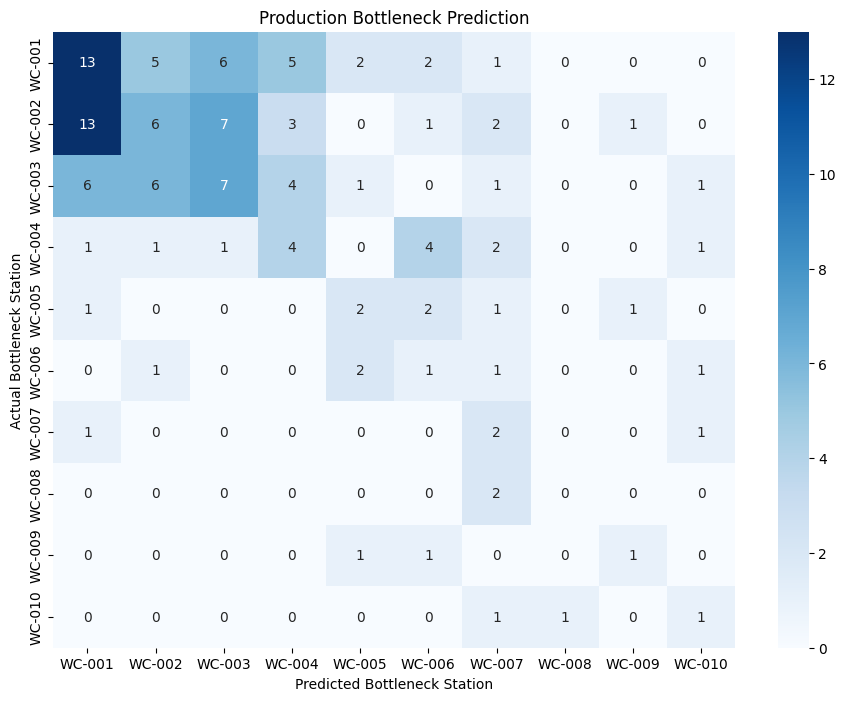


Model saved successfully!

========== SAMPLE PREDICTION ==========
Predicted bottleneck station: WC-001

Station prediction scores:


,Station,Model Score (%)
0,WC-001,37.924879
1,WC-002,28.551170
2,WC-003,23.975498
9,WC-010,2.988303
7,WC-008,1.869540
6,WC-007,1.743019
3,WC-004,0.987733
5,WC-006,0.802124
8,WC-009,0.620878
4,WC-005,0.536855



Actual station: WC-003


In [13]:

# ============================================================
# AUTOMOTIVE MODEL 2: PRODUCTION BOTTLENECK CLASSIFICATION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# 1. Prepare automotive dataset

target = "bottleneck_station_id"

data = auto.copy()

data = data.dropna(subset=[target])

# 2. Remove target-related and leakage-prone columns

excluded_keywords = [
    "bottleneck",
    "station_id",
    "secondary",
    "target",
    "label",
    "timestamp",
    "date",
    "product_id",
    "record_id",
    "failure_mode"
]

excluded_columns = [
    col for col in data.columns
    if any(word in col.lower() for word in excluded_keywords)
]

# Keep only useful numeric and low-cardinality categorical features

candidate_columns = [
    col for col in data.columns
    if col != target and col not in excluded_columns
]

feature_columns = []

for col in candidate_columns:

    if data[col].nunique(dropna=True) <= 1:
        continue

    if pd.api.types.is_numeric_dtype(data[col]):
        feature_columns.append(col)

    elif (
        data[col].dtype == "object"
        or isinstance(data[col].dtype, pd.CategoricalDtype)
        or pd.api.types.is_bool_dtype(data[col])
    ):
        if data[col].nunique(dropna=True) <= 30:
            feature_columns.append(col)

if not feature_columns:
    raise ValueError("No usable input features found.")

X = data[feature_columns].copy()
y = data[target].astype(str)

print("Selected input features:")
print(feature_columns)

print("\nTarget distribution:")
print(y.value_counts())

print("\nDataset shape:", X.shape)

# 3. Identify numeric and categorical features

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = [
    col for col in feature_columns
    if col not in numeric_features
]

# 4. Preprocessing

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

# 5. Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

# 6. Create and train Random Forest

bottleneck_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced_subsample",
        random_state=42,
        min_samples_leaf=2,
        n_jobs=-1
    ))
])

bottleneck_model.fit(X_train, y_train)

print("\nModel training completed!")

# 7. Evaluate the model

predictions = bottleneck_model.predict(X_test)

print("\n========== MODEL EVALUATION ==========")

print("Accuracy:",
      round(accuracy_score(y_test, predictions), 4))

print("Balanced Accuracy:",
      round(balanced_accuracy_score(y_test, predictions), 4))

print("Precision (Macro):",
      round(precision_score(
          y_test, predictions,
          average="macro", zero_division=0
      ), 4))

print("Recall (Macro):",
      round(recall_score(
          y_test, predictions,
          average="macro", zero_division=0
      ), 4))

print("F1 Score (Macro):",
      round(f1_score(
          y_test, predictions,
          average="macro", zero_division=0
      ), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    predictions,
    zero_division=0
))

# 8. Confusion matrix

labels = sorted(y.unique())

cm = confusion_matrix(
    y_test,
    predictions,
    labels=labels
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted Bottleneck Station")
plt.ylabel("Actual Bottleneck Station")
plt.title("Production Bottleneck Prediction")
plt.show()

# 9. Save trained model

joblib.dump(
    {
        "model": bottleneck_model,
        "features": feature_columns,
        "target": target
    },
    "automotive_bottleneck_model.pkl"
)

print("\nModel saved successfully!")

# 10. Test one prediction

sample = X_test.iloc[[0]]

predicted_station = bottleneck_model.predict(sample)[0]

probabilities = bottleneck_model.predict_proba(sample)[0]

class_names = bottleneck_model.named_steps[
    "classifier"
].classes_

probability_results = pd.DataFrame({
    "Station": class_names,
    "Model Score (%)": probabilities * 100
}).sort_values(
    "Model Score (%)",
    ascending=False
)

print("\n========== SAMPLE PREDICTION ==========")

print("Predicted bottleneck station:",
      predicted_station)

print("\nStation prediction scores:")
display(probability_results)

print("\nActual station:", y_test.iloc[0])


1. DATASET OVERVIEW
Dataset shape: (660, 118)
Number of rows: 660
Number of columns: 118

Data types:


,count
float64,70
object,32
int64,16



First 5 records:


,line_id,plant_id,work_center_id,shift_id,shift_date,shift_number,shift_duration_minutes,product_id,product_family,production_order_id,...,direct_labour_cost_usd,overhead_cost_usd,material_cost_per_unit_usd,scrap_cost_usd,rework_cost_usd,downtime_cost_per_minute_usd,total_downtime_cost_usd,cost_of_poor_quality_usd,value_added_ratio_pct,production_cost_per_unit_usd
1,MFG-LINE-PLT-005-05,PLT-005,WC-048,SHF-PLT-005-20200508-1,2020-05-08,1,473.0,PRD-2020-SKU-05736,automotive_body,WO-2020-36066,...,8404.33,16045.01,30.59,0.0,7.65,200,22700.0,4547.65,40.8,120.9218
2,MFG-LINE-PLT-005-01,PLT-005,WC-039,SHF-PLT-005-20221016-3,2022-10-16,3,450.2,PRD-2022-SKU-04660,automotive_body,WO-2022-67019,...,683.77,1120.42,28.64,0.0,7.16,200,26220.0,5251.16,29.2,33.3516
6,MFG-LINE-PLT-005-05,PLT-005,WC-003,SHF-PLT-005-20240625-3,2024-06-25,3,435.3,PRD-2024-SKU-02707,automotive_body,WO-2024-01817,...,6166.39,7796.90,33.88,0.0,8.47,200,5120.0,1032.47,27.5,79.6224
7,MFG-LINE-PLT-005-04,PLT-005,WC-017,SHF-PLT-005-20240327-1,2024-03-27,1,456.6,PRD-2024-SKU-07919,automotive_body,WO-2024-13111,...,3400.15,6198.53,57.40,0.0,14.35,200,9700.0,1954.35,71.8,78.1658
16,MFG-LINE-PLT-005-03,PLT-005,WC-007,SHF-PLT-005-20231218-1,2023-12-18,1,478.1,PRD-2023-SKU-06623,automotive_body,WO-2023-94883,...,970.36,1662.49,53.07,0.0,13.27,200,9480.0,1909.27,56.3,59.5421



Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
line_id,660,8,MFG-LINE-PLT-005-02,92,NaN,NaN,NaN,NaN,NaN,NaN,NaN
plant_id,660,2,PLT-005,509,NaN,NaN,NaN,NaN,NaN,NaN,NaN
work_center_id,660,49,WC-035,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
shift_id,660,642,SHF-PLT-009-20231003-1,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
shift_date,660,563,2024-07-23,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
downtime_cost_per_minute_usd,660.0,NaN,NaN,NaN,200.0,0.0,200.0,200.0,200.0,200.0,200.0
total_downtime_cost_usd,660.0,NaN,NaN,NaN,13674.012015,10163.731222,0.0,6475.0,11560.0,19400.0,59040.0
cost_of_poor_quality_usd,660.0,NaN,NaN,NaN,2745.768288,2032.766536,3.62,1306.66,2324.415,3888.8675,11819.56
value_added_ratio_pct,660.0,NaN,NaN,NaN,50.022727,14.04797,25.1,38.7,49.25,62.325,74.8



2. DATA QUALITY CHECK


,Missing_Count,Missing_Percentage


Duplicate rows: 0

3. BOTTLENECK TARGET DISTRIBUTION


,Count,Percentage
bottleneck_station_id,,
WC-001,168,25.45
WC-002,164,24.85
WC-003,131,19.85
WC-004,69,10.45
WC-005,33,5.00
WC-006,31,4.70
WC-007,21,3.18
WC-010,16,2.42
WC-009,16,2.42


Majority-class baseline accuracy: 25.45 %


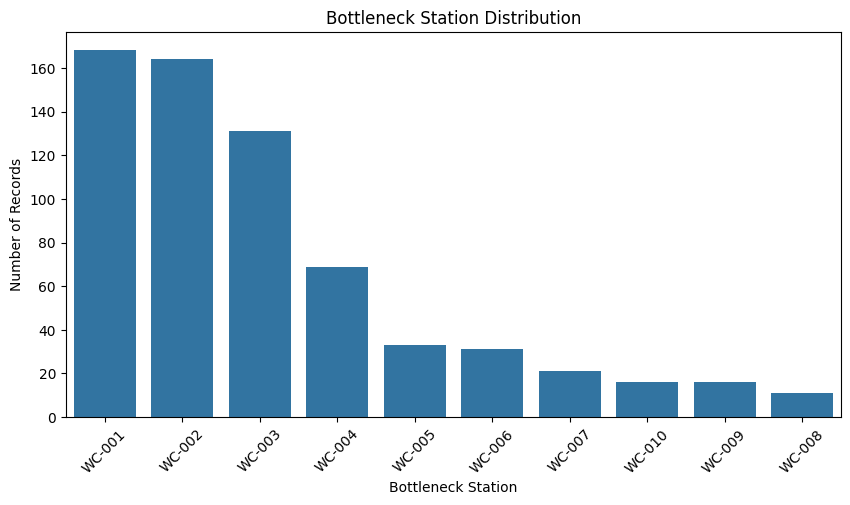


4. PRODUCTION LINE AND PLANT ANALYSIS

Unique values in line_id : 8
line_id
MFG-LINE-PLT-005-02    92
MFG-LINE-PLT-005-05    89
MFG-LINE-PLT-005-06    89
MFG-LINE-PLT-005-04    88
MFG-LINE-PLT-009-02    82
MFG-LINE-PLT-005-03    77
MFG-LINE-PLT-005-01    74
MFG-LINE-PLT-009-01    69
Name: count, dtype: int64

Unique values in plant_id : 2
plant_id
PLT-005    509
PLT-009    151
Name: count, dtype: int64

Unique values in shift_number : 3
shift_number
1    291
2    229
3    140
Name: count, dtype: int64

Bottleneck variation by production line:


,total_records,unique_bottlenecks,most_common_bottleneck
line_id,,,
MFG-LINE-PLT-005-02,92,6,WC-001
MFG-LINE-PLT-005-05,89,3,WC-002
MFG-LINE-PLT-005-06,89,10,WC-007
MFG-LINE-PLT-005-04,88,4,WC-001
MFG-LINE-PLT-009-02,82,3,WC-003
MFG-LINE-PLT-005-03,77,2,WC-001
MFG-LINE-PLT-005-01,74,4,WC-004
MFG-LINE-PLT-009-01,69,10,WC-001



5. BOTTLENECK DISTRIBUTION BY PLANT


bottleneck_station_id,WC-001,WC-002,WC-003,WC-004,WC-005,WC-006,WC-007,WC-008,WC-009,WC-010
plant_id,,,,,,,,,,
PLT-005,137,132,89,65,25,23,12,7,8,11
PLT-009,31,32,42,4,8,8,9,4,8,5



Number of bottleneck types per plant:


,bottleneck_station_id
plant_id,
PLT-005,10
PLT-009,10



6. PRODUCTION FEATURES BY BOTTLENECK


,actual_cycle_time_avg_seconds,actual_cycle_time_std_seconds,actual_cycle_time_min_seconds,actual_cycle_time_max_seconds,takt_time_seconds,designed_cycle_time_seconds,wip_queue_avg_units,wip_queue_max_units,throughput_rate_actual_uph,throughput_rate_design_uph,downtime_unplanned_minutes,downtime_planned_minutes,oee_availability,oee_performance,oee_overall,equipment_condition_score,equipment_age_years,operator_utilisation_pct
bottleneck_station_id,,,,,,,,,,,,,,,,,,
WC-001,62.71,4.32,56.35,133.12,54.07,50.79,1.49,3.96,61.94,75.26,75.39,1.34,0.83,0.77,0.64,5.88,21.71,78.34
WC-002,62.01,4.03,55.70,126.10,53.49,50.14,1.32,3.61,62.24,76.34,62.18,2.46,0.86,0.77,0.66,5.82,21.17,78.96
WC-003,60.32,4.24,54.14,126.35,50.84,47.66,1.63,4.47,66.19,81.55,67.32,2.41,0.85,0.74,0.63,6.00,17.68,77.02
WC-004,60.00,5.71,53.51,130.47,49.62,47.59,1.39,3.83,66.20,81.09,66.73,1.58,0.85,0.76,0.65,6.17,17.63,75.48
WC-005,72.19,5.76,65.49,146.08,62.02,59.54,1.53,3.85,51.96,62.89,50.09,4.35,0.89,0.79,0.70,6.33,17.15,73.43
WC-006,68.13,5.63,61.36,136.50,60.62,57.66,0.96,2.55,54.58,64.75,64.81,4.22,0.85,0.79,0.67,6.21,15.20,77.94
WC-007,90.42,7.01,81.63,194.96,69.29,69.77,1.72,4.38,40.91,51.99,78.34,1.10,0.83,0.72,0.59,5.57,30.43,79.64
WC-008,87.08,6.25,78.86,206.29,69.95,70.56,2.15,6.18,42.06,51.39,65.32,0.00,0.85,0.74,0.63,5.32,30.68,78.68
WC-009,82.51,6.71,74.06,161.26,68.55,68.90,1.87,5.12,44.19,52.66,100.08,1.41,0.77,0.72,0.57,5.35,30.15,77.88


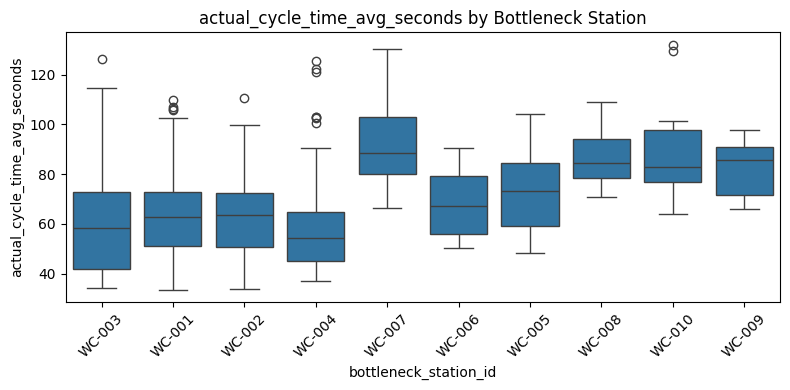

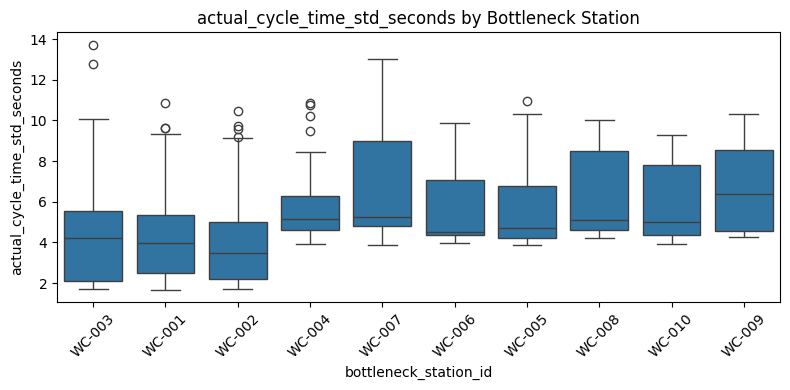

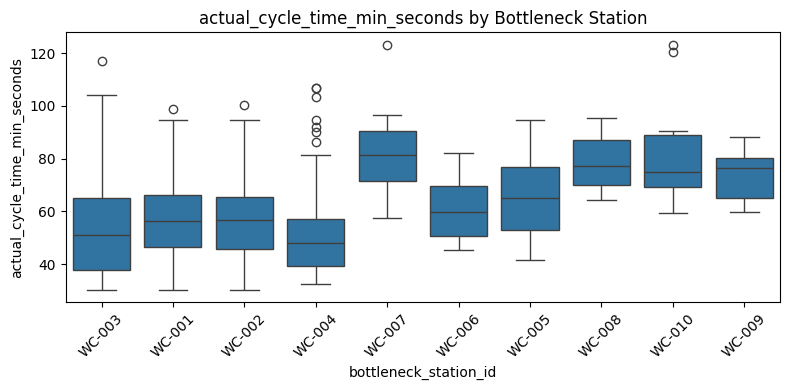

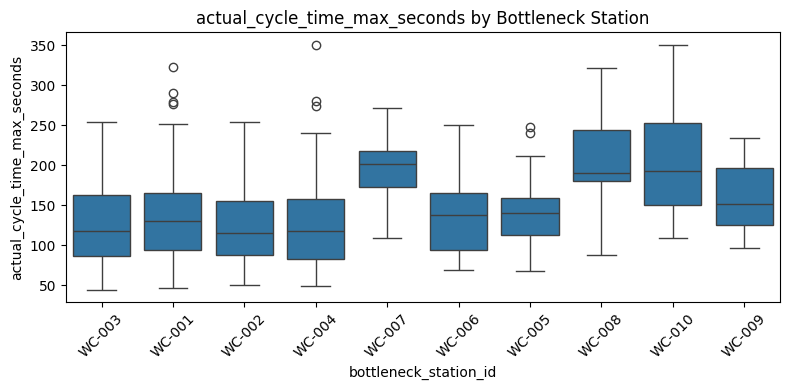

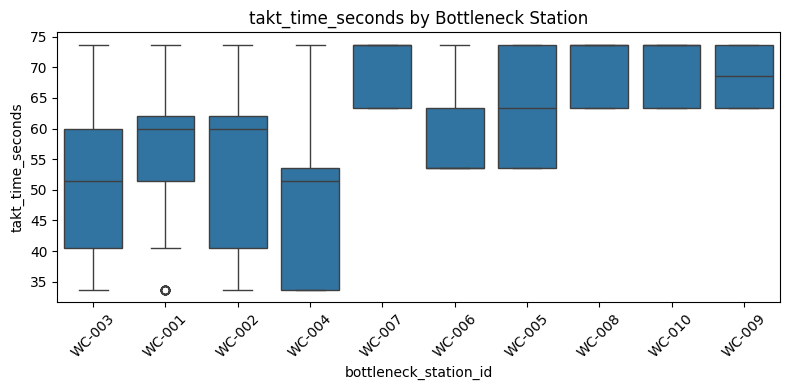

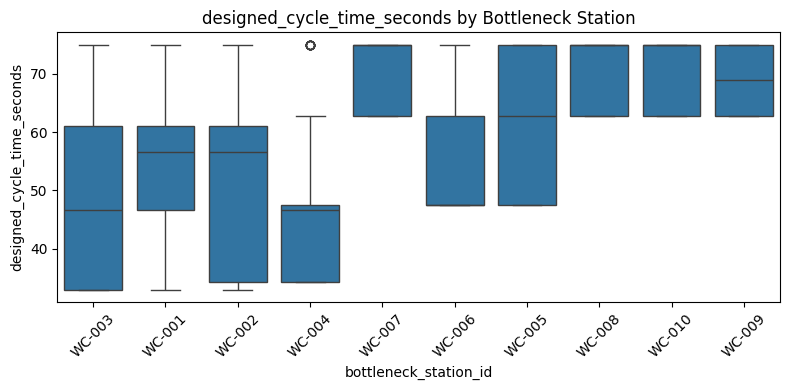


7. NUMERICAL FEATURE CORRELATION


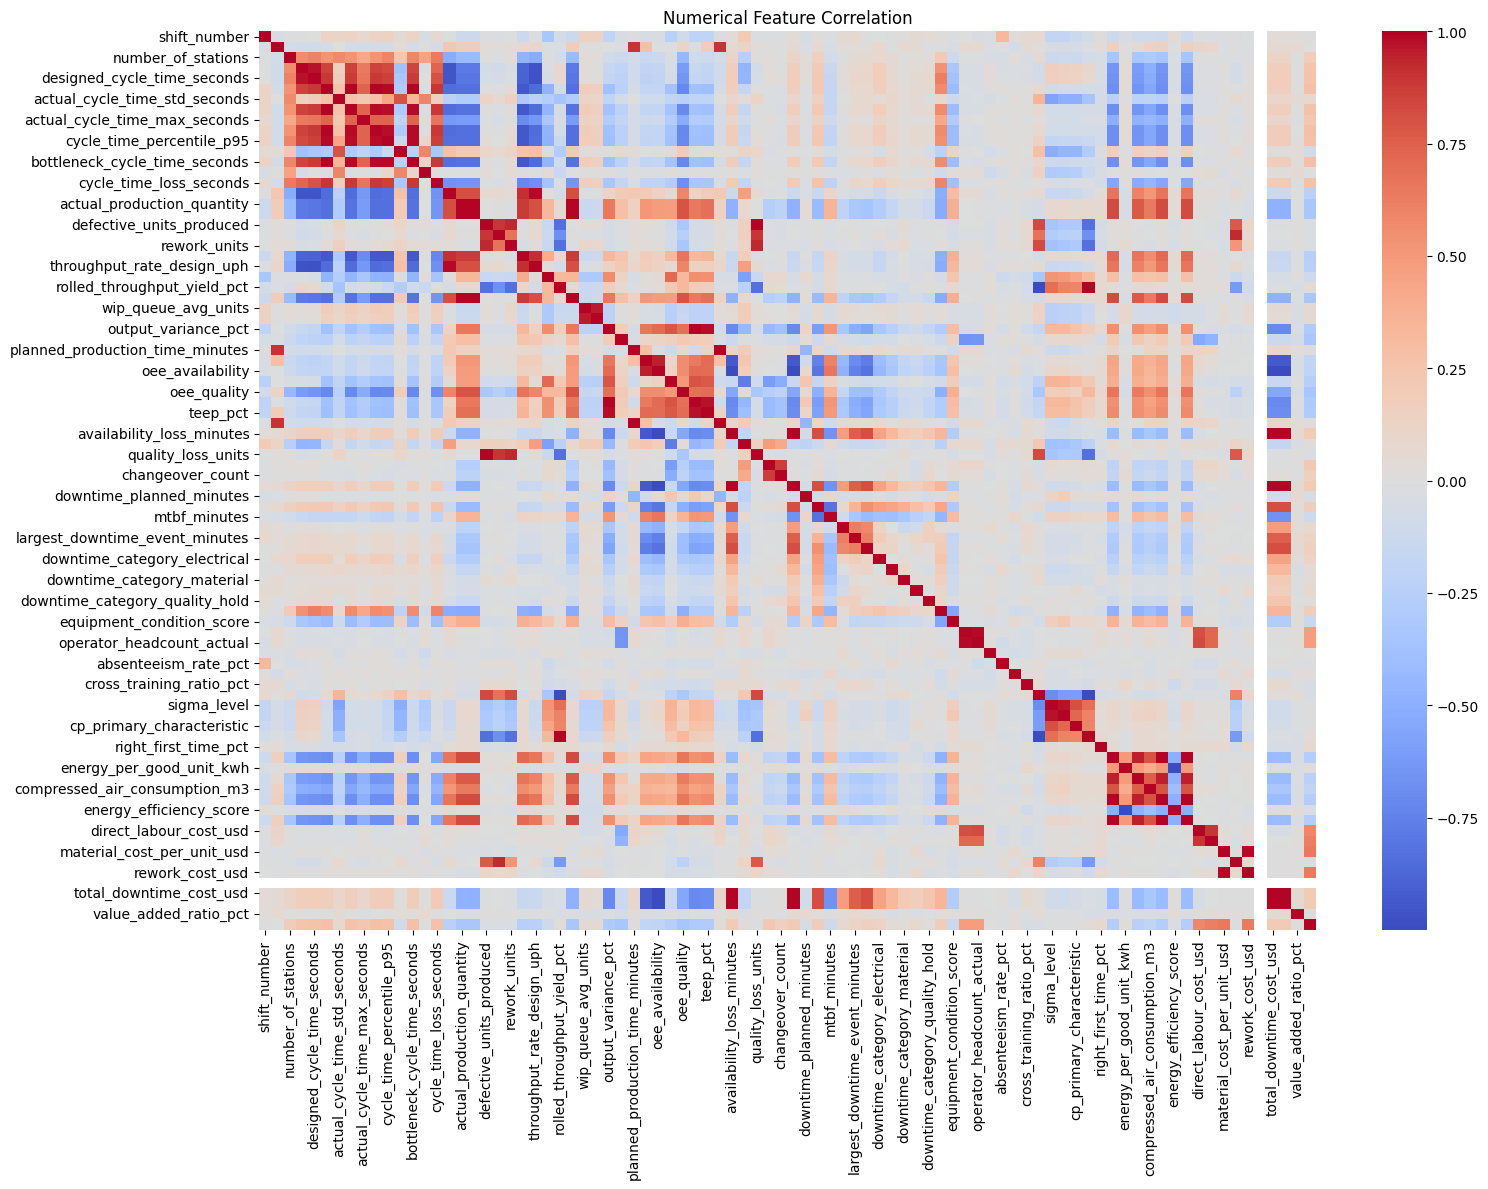


8. POTENTIAL DATA LEAKAGE FEATURES
Columns requiring leakage review:
- bottleneck_station_id
- bottleneck_cycle_time_seconds
- bottleneck_utilisation_pct
- secondary_bottleneck_station_id
- six_big_losses_breakdown
- oee_loss_primary_driver
- secondary_defect_type

These columns need investigation before training. They are not automatically all leakage.

9. CHRONOLOGICAL DATA CHECK
Possible time columns: ['shift_date', 'takt_time_seconds', 'designed_cycle_time_seconds', 'actual_cycle_time_avg_seconds', 'actual_cycle_time_std_seconds', 'actual_cycle_time_min_seconds', 'actual_cycle_time_max_seconds', 'cycle_time_percentile_p50', 'cycle_time_percentile_p95', 'cycle_time_cov', 'bottleneck_cycle_time_seconds', 'cycle_time_loss_seconds', 'planned_production_time_minutes', 'available_time_minutes', 'changeover_time_minutes', 'downtime_unplanned_minutes', 'downtime_planned_minutes', 'downtime_event_count', 'largest_downtime_event_minutes', 'downtime_category_mechanical', 'downtime_category_e

,Data_Type,Unique_Values
cost_of_poor_quality_usd,float64,660
direct_labour_cost_usd,float64,660
overhead_cost_usd,float64,659
production_cost_per_unit_usd,float64,659
production_order_id,object,659
...,...,...
industry_sector,object,1
product_family,object,1
secondary_defect_type,object,1
primary_defect_type,object,1



11. POSSIBLE IDENTIFIER COLUMNS
line_id | Unique values: 8 | Total records: 660
plant_id | Unique values: 2 | Total records: 660
work_center_id | Unique values: 49 | Total records: 660
shift_id | Unique values: 642 | Total records: 660
product_id | Unique values: 656 | Total records: 660
production_order_id | Unique values: 659 | Total records: 660
bottleneck_station_id | Unique values: 10 | Total records: 660
secondary_bottleneck_station_id | Unique values: 10 | Total records: 660
ergonomic_incident_flag | Unique values: 2 | Total records: 660
shift_supervisor_id | Unique values: 192 | Total records: 660

12. FINAL DIAGNOSTIC SUMMARY
Total records: 660
Total features: 118
Number of bottleneck classes: 10
Majority class baseline: 25.45 %
Total missing values: 0
Duplicate records: 0
Unique production lines: 8
Unique plants: 2

DIAGNOSTICS COMPLETED!


In [14]:

# ============================================================
# AUTOMOTIVE MODEL 2 - COMPLETE DATASET DIAGNOSTICS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# ------------------------------------------------------------
# 1. BASIC DATASET INFORMATION
# ------------------------------------------------------------

print("=" * 65)
print("1. DATASET OVERVIEW")
print("=" * 65)

print("Dataset shape:", auto.shape)
print("Number of rows:", len(auto))
print("Number of columns:", len(auto.columns))

print("\nData types:")
display(auto.dtypes.value_counts())

print("\nFirst 5 records:")
display(auto.head())

print("\nStatistical summary:")
display(auto.describe(include="all").T)


# ------------------------------------------------------------
# 2. MISSING VALUES AND DUPLICATES
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("2. DATA QUALITY CHECK")
print("=" * 65)

missing = auto.isnull().sum()

missing_report = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": (
        missing / len(auto) * 100
    ).round(2)
})

display(
    missing_report[
        missing_report["Missing_Count"] > 0
    ].sort_values(
        "Missing_Percentage",
        ascending=False
    )
)

print("Duplicate rows:", auto.duplicated().sum())


# ------------------------------------------------------------
# 3. TARGET DISTRIBUTION
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("3. BOTTLENECK TARGET DISTRIBUTION")
print("=" * 65)

target = "bottleneck_station_id"

if target not in auto.columns:
    raise ValueError("Bottleneck target column not found!")

target_counts = auto[target].value_counts()

target_report = pd.DataFrame({
    "Count": target_counts,
    "Percentage": (
        target_counts / len(auto) * 100
    ).round(2)
})

display(target_report)

majority_baseline = (
    target_counts.max() / target_counts.sum()
)

print(
    "Majority-class baseline accuracy:",
    round(majority_baseline * 100, 2),
    "%"
)

plt.figure(figsize=(10, 5))

sns.countplot(
    data=auto,
    x=target,
    order=target_counts.index
)

plt.title("Bottleneck Station Distribution")
plt.xlabel("Bottleneck Station")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.show()


# ------------------------------------------------------------
# 4. PRODUCTION LINE AND PLANT ANALYSIS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("4. PRODUCTION LINE AND PLANT ANALYSIS")
print("=" * 65)

for col in ["line_id", "plant_id", "shift_number"]:
    if col in auto.columns:
        print("\nUnique values in", col, ":",
              auto[col].nunique())

        print(auto[col].value_counts().head(15))

if "line_id" in auto.columns:

    line_analysis = auto.groupby("line_id").agg(
        total_records=(target, "size"),
        unique_bottlenecks=(target, "nunique"),
        most_common_bottleneck=(
            target,
            lambda x: x.mode().iloc[0]
        )
    )

    print("\nBottleneck variation by production line:")
    display(line_analysis.sort_values(
        "total_records",
        ascending=False
    ).head(25))


# ------------------------------------------------------------
# 5. BOTTLENECK DISTRIBUTION BY PLANT
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("5. BOTTLENECK DISTRIBUTION BY PLANT")
print("=" * 65)

if "plant_id" in auto.columns:

    plant_table = pd.crosstab(
        auto["plant_id"],
        auto[target]
    )

    display(plant_table)

    print("\nNumber of bottleneck types per plant:")
    display(
        auto.groupby("plant_id")[target]
        .nunique()
    )


# ------------------------------------------------------------
# 6. NUMERICAL FEATURE RELATIONSHIPS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("6. PRODUCTION FEATURES BY BOTTLENECK")
print("=" * 65)

selected_features = [
    "actual_cycle_time_avg_seconds",
    "actual_cycle_time_std_seconds",
    "actual_cycle_time_min_seconds",
    "actual_cycle_time_max_seconds",
    "takt_time_seconds",
    "designed_cycle_time_seconds",
    "wip_queue_avg_units",
    "wip_queue_max_units",
    "throughput_rate_actual_uph",
    "throughput_rate_design_uph",
    "downtime_unplanned_minutes",
    "downtime_planned_minutes",
    "oee_availability",
    "oee_performance",
    "oee_overall",
    "equipment_condition_score",
    "equipment_age_years",
    "operator_utilisation_pct"
]

available_features = [
    col for col in selected_features
    if col in auto.columns
    and pd.api.types.is_numeric_dtype(auto[col])
]

if available_features:

    feature_comparison = auto.groupby(target)[
        available_features
    ].mean().round(2)

    display(feature_comparison)

    for col in available_features[:6]:

        plt.figure(figsize=(8, 4))

        sns.boxplot(
            data=auto,
            x=target,
            y=col
        )

        plt.title(f"{col} by Bottleneck Station")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()


# ------------------------------------------------------------
# 7. CORRELATION ANALYSIS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("7. NUMERICAL FEATURE CORRELATION")
print("=" * 65)

numeric_data = auto.select_dtypes(
    include=["number"]
)

correlation = numeric_data.corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0
)

plt.title("Numerical Feature Correlation")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. POTENTIAL DATA LEAKAGE CHECK
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("8. POTENTIAL DATA LEAKAGE FEATURES")
print("=" * 65)

leakage_keywords = [
    "bottleneck",
    "secondary",
    "loss_primary",
    "six_big_losses",
    "bottleneck_utilisation"
]

potential_leakage = [
    col for col in auto.columns
    if any(
        word in col.lower()
        for word in leakage_keywords
    )
]

print("Columns requiring leakage review:")

for col in potential_leakage:
    print("-", col)

print(
    "\nThese columns need investigation before training."
    " They are not automatically all leakage."
)


# ------------------------------------------------------------
# 9. CHECK TIME AND SHIFT INFORMATION
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("9. CHRONOLOGICAL DATA CHECK")
print("=" * 65)

time_columns = [
    col for col in auto.columns
    if any(
        word in col.lower()
        for word in ["date", "time", "timestamp"]
    )
]

shift_columns = [
    col for col in auto.columns
    if "shift" in col.lower()
]

print("Possible time columns:", time_columns)
print("Possible shift columns:", shift_columns)

for col in time_columns:
    print("\n", col)
    print(auto[col].head(10).tolist())

for col in shift_columns:
    print("\n", col)
    print(auto[col].value_counts().head(15))


# ------------------------------------------------------------
# 10. FEATURE CARDINALITY CHECK
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("10. FEATURE CARDINALITY")
print("=" * 65)

cardinality = pd.DataFrame({
    "Data_Type": auto.dtypes.astype(str),
    "Unique_Values": auto.nunique(dropna=True)
})

display(
    cardinality.sort_values(
        "Unique_Values",
        ascending=False
    )
)


# ------------------------------------------------------------
# 11. IDENTIFY POSSIBLE ID FEATURES
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("11. POSSIBLE IDENTIFIER COLUMNS")
print("=" * 65)

id_columns = [
    col for col in auto.columns
    if any(
        word in col.lower()
        for word in ["id", "code", "serial"]
    )
]

for col in id_columns:
    print(
        col,
        "| Unique values:",
        auto[col].nunique(),
        "| Total records:",
        len(auto)
    )


# ------------------------------------------------------------
# 12. FINAL DIAGNOSTIC SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("12. FINAL DIAGNOSTIC SUMMARY")
print("=" * 65)

print("Total records:", len(auto))
print("Total features:", len(auto.columns))
print("Number of bottleneck classes:", auto[target].nunique())
print("Majority class baseline:",
      round(majority_baseline * 100, 2), "%")

print("Total missing values:", auto.isnull().sum().sum())
print("Duplicate records:", auto.duplicated().sum())

if "line_id" in auto.columns:
    print("Unique production lines:", auto["line_id"].nunique())

if "plant_id" in auto.columns:
    print("Unique plants:", auto["plant_id"].nunique())

print("\nDIAGNOSTICS COMPLETED!")


In [15]:

# ============================================================
# MODEL 2 - BOTTLENECK FEATURE-TARGET ANALYSIS
# ============================================================

import pandas as pd
import numpy as np

from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder

target = "bottleneck_station_id"

# 1. Bottleneck distribution by production line

print("BOTTLENECK DISTRIBUTION BY LINE")

line_station_table = pd.crosstab(
    auto["line_id"],
    auto[target]
)

display(line_station_table)

# 2. Percentage of each bottleneck within each line

print("\nBOTTLENECK PERCENTAGES BY LINE")

display(
    pd.crosstab(
        auto["line_id"],
        auto[target],
        normalize="index"
    ).round(2) * 100
)

# 3. Bottleneck distribution by plant

print("\nBOTTLENECK DISTRIBUTION BY PLANT")

display(
    pd.crosstab(
        auto["plant_id"],
        auto[target]
    )
)

# 4. Check whether line IDs strongly identify the target

line_dominance = (
    auto.groupby("line_id")[target]
    .agg(
        records="count",
        unique_stations="nunique",
        dominant_station=lambda x: x.mode().iloc[0],
        dominant_percentage=lambda x:
            x.value_counts(normalize=True).max() * 100
    )
)

print("\nLINE-LEVEL TARGET CONSISTENCY")
display(line_dominance.round(2))

# 5. Examine production variables by bottleneck class

features = [
    "actual_cycle_time_avg_seconds",
    "actual_cycle_time_max_seconds",
    "actual_cycle_time_std_seconds",
    "takt_time_seconds",
    "wip_queue_avg_units",
    "wip_queue_max_units",
    "downtime_unplanned_minutes",
    "throughput_rate_actual_uph",
    "oee_availability",
    "equipment_condition_score"
]

features = [
    c for c in features
    if c in auto.columns
]

print("\nFEATURE MEANS BY BOTTLENECK")
display(
    auto.groupby(target)[features]
    .mean()
    .round(2)
)

# 6. Mutual information ranking

X_mi = auto[features].copy()

X_mi = X_mi.fillna(
    X_mi.median(numeric_only=True)
)

encoder = LabelEncoder()
y_encoded = encoder.fit_transform(auto[target])

mi_scores = mutual_info_classif(
    X_mi,
    y_encoded,
    random_state=42
)

mi_results = pd.DataFrame({
    "Feature": features,
    "Mutual Information": mi_scores
}).sort_values(
    "Mutual Information",
    ascending=False
)

print("\nFEATURE IMPORTANCE - MUTUAL INFORMATION")
display(mi_results)

print("\nANALYSIS COMPLETED")


BOTTLENECK DISTRIBUTION BY LINE


bottleneck_station_id,WC-001,WC-002,WC-003,WC-004,WC-005,WC-006,WC-007,WC-008,WC-009,WC-010
line_id,,,,,,,,,,
MFG-LINE-PLT-005-01,19,17,14,24,0,0,0,0,0,0
MFG-LINE-PLT-005-02,16,16,15,14,15,16,0,0,0,0
MFG-LINE-PLT-005-03,40,37,0,0,0,0,0,0,0,0
MFG-LINE-PLT-005-04,26,22,23,17,0,0,0,0,0,0
MFG-LINE-PLT-005-05,27,34,28,0,0,0,0,0,0,0
MFG-LINE-PLT-005-06,9,6,9,10,10,7,12,7,8,11
MFG-LINE-PLT-009-01,10,6,7,4,8,8,9,4,8,5
MFG-LINE-PLT-009-02,21,26,35,0,0,0,0,0,0,0



BOTTLENECK PERCENTAGES BY LINE


bottleneck_station_id,WC-001,WC-002,WC-003,WC-004,WC-005,WC-006,WC-007,WC-008,WC-009,WC-010
line_id,,,,,,,,,,
MFG-LINE-PLT-005-01,26.0,23.0,19.0,32.0,0.0,0.0,0.0,0.0,0.0,0.0
MFG-LINE-PLT-005-02,17.0,17.0,16.0,15.0,16.0,17.0,0.0,0.0,0.0,0.0
MFG-LINE-PLT-005-03,52.0,48.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
MFG-LINE-PLT-005-04,30.0,25.0,26.0,19.0,0.0,0.0,0.0,0.0,0.0,0.0
MFG-LINE-PLT-005-05,30.0,38.0,31.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
MFG-LINE-PLT-005-06,10.0,7.0,10.0,11.0,11.0,8.0,13.0,8.0,9.0,12.0
MFG-LINE-PLT-009-01,14.0,9.0,10.0,6.0,12.0,12.0,13.0,6.0,12.0,7.0
MFG-LINE-PLT-009-02,26.0,32.0,43.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



BOTTLENECK DISTRIBUTION BY PLANT


bottleneck_station_id,WC-001,WC-002,WC-003,WC-004,WC-005,WC-006,WC-007,WC-008,WC-009,WC-010
plant_id,,,,,,,,,,
PLT-005,137,132,89,65,25,23,12,7,8,11
PLT-009,31,32,42,4,8,8,9,4,8,5


... (3 outputs left out)

,actual_cycle_time_avg_seconds,actual_cycle_time_max_seconds,actual_cycle_time_std_seconds,takt_time_seconds,wip_queue_avg_units,wip_queue_max_units,downtime_unplanned_minutes,throughput_rate_actual_uph,oee_availability,equipment_condition_score
bottleneck_station_id,,,,,,,,,,
WC-001,62.71,133.12,4.32,54.07,1.49,3.96,75.39,61.94,0.83,5.88
WC-002,62.01,126.10,4.03,53.49,1.32,3.61,62.18,62.24,0.86,5.82
WC-003,60.32,126.35,4.24,50.84,1.63,4.47,67.32,66.19,0.85,6.00
WC-004,60.00,130.47,5.71,49.62,1.39,3.83,66.73,66.20,0.85,6.17
WC-005,72.19,146.08,5.76,62.02,1.53,3.85,50.09,51.96,0.89,6.33
WC-006,68.13,136.50,5.63,60.62,0.96,2.55,64.81,54.58,0.85,6.21
WC-007,90.42,194.96,7.01,69.29,1.72,4.38,78.34,40.91,0.83,5.57
WC-008,87.08,206.29,6.25,69.95,2.15,6.18,65.32,42.06,0.85,5.32
WC-009,82.51,161.26,6.71,68.55,1.87,5.12,100.08,44.19,0.77,5.35



FEATURE IMPORTANCE - MUTUAL INFORMATION


,Feature,Mutual Information
3,takt_time_seconds,0.399019
2,actual_cycle_time_std_seconds,0.194063
1,actual_cycle_time_max_seconds,0.122965
7,throughput_rate_actual_uph,0.101764
0,actual_cycle_time_avg_seconds,0.093252
8,oee_availability,0.025028
9,equipment_condition_score,0.015946
6,downtime_unplanned_minutes,0.013436
5,wip_queue_max_units,0.000000
4,wip_queue_avg_units,0.000000



ANALYSIS COMPLETED


Selected features: ['actual_cycle_time_avg_seconds', 'actual_cycle_time_std_seconds', 'actual_cycle_time_max_seconds', 'takt_time_seconds', 'designed_cycle_time_seconds', 'wip_queue_avg_units', 'wip_queue_max_units', 'downtime_unplanned_minutes', 'throughput_rate_actual_uph', 'throughput_rate_design_uph', 'equipment_condition_score', 'equipment_age_years', 'operator_utilisation_pct', 'operator_headcount_actual', 'line_type', 'automation_level', 'line_configuration']
Total features: 17
Records: 660

MODEL COMPARISON


,Model,Accuracy,Balanced Accuracy,Precision Macro,Recall Macro,F1 Macro
2,Extra Trees,0.2652,0.3484,0.2365,0.3484,0.2440
0,Decision Tree,0.2803,0.1905,0.1957,0.1905,0.1868
1,Random Forest,0.2500,0.2204,0.1788,0.2204,0.1808



Best model: Extra Trees

Classification report:
              precision    recall  f1-score   support

      WC-001       0.42      0.15      0.22        34
      WC-002       0.47      0.27      0.35        33
      WC-003       0.33      0.23      0.27        26
      WC-004       0.17      0.36      0.23        14
      WC-005       0.12      0.14      0.13         7
      WC-006       0.25      0.67      0.36         6
      WC-007       0.20      0.50      0.29         4
      WC-008       0.20      0.50      0.29         2
      WC-009       0.00      0.00      0.00         3
      WC-010       0.20      0.67      0.31         3

    accuracy                           0.27       132
   macro avg       0.24      0.35      0.24       132
weighted avg       0.34      0.27      0.26       132


TOP 15 IMPORTANT FEATURES


,Feature,Importance
2,numeric__actual_cycle_time_max_seconds,0.077353
13,numeric__operator_headcount_actual,0.076237
12,numeric__operator_utilisation_pct,0.075126
8,numeric__throughput_rate_actual_uph,0.068223
1,numeric__actual_cycle_time_std_seconds,0.067217
6,numeric__wip_queue_max_units,0.063145
5,numeric__wip_queue_avg_units,0.061865
0,numeric__actual_cycle_time_avg_seconds,0.058866
7,numeric__downtime_unplanned_minutes,0.054046
10,numeric__equipment_condition_score,0.047622


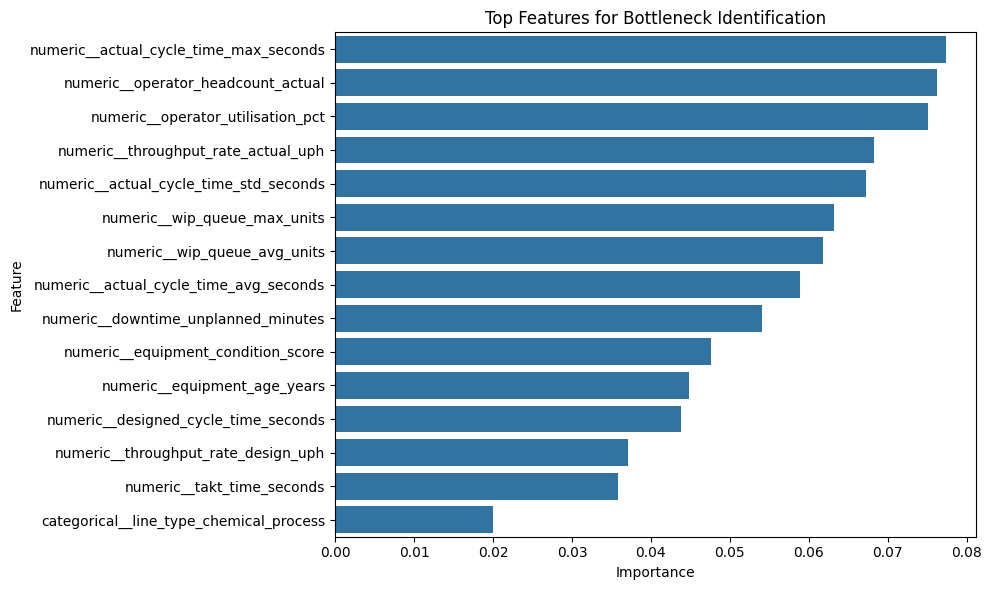


Improved model saved successfully!


In [16]:

# ============================================================
# AUTOMOTIVE MODEL 2 - IMPROVED MODEL EXPERIMENT
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier
)

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# ------------------------------------------------------------
# 1. Define meaningful features
# ------------------------------------------------------------

target = "bottleneck_station_id"

numeric_features = [
    "actual_cycle_time_avg_seconds",
    "actual_cycle_time_std_seconds",
    "actual_cycle_time_max_seconds",
    "takt_time_seconds",
    "designed_cycle_time_seconds",
    "wip_queue_avg_units",
    "wip_queue_max_units",
    "downtime_unplanned_minutes",
    "throughput_rate_actual_uph",
    "throughput_rate_design_uph",
    "equipment_condition_score",
    "equipment_age_years",
    "operator_utilisation_pct",
    "operator_headcount_actual"
]

categorical_features = [
    "line_type",
    "automation_level",
    "line_configuration"
]

numeric_features = [
    c for c in numeric_features if c in auto.columns
]

categorical_features = [
    c for c in categorical_features if c in auto.columns
]

features = numeric_features + categorical_features

data = auto[features + [target]].copy()

data = data.dropna(subset=[target])

X = data[features]
y = data[target].astype(str)

print("Selected features:", features)
print("Total features:", len(features))
print("Records:", len(data))

# ------------------------------------------------------------
# 2. Preprocessing
# ------------------------------------------------------------

preprocessor = ColumnTransformer([
    (
        "numeric",
        SimpleImputer(strategy="median"),
        numeric_features
    ),
    (
        "categorical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(
                handle_unknown="ignore"
            ))
        ]),
        categorical_features
    )
])

# ------------------------------------------------------------
# 3. Train-test split
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# ------------------------------------------------------------
# 4. Compare algorithms
# ------------------------------------------------------------

models = {
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        max_depth=8,
        min_samples_leaf=3,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=400,
        class_weight="balanced_subsample",
        min_samples_leaf=2,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=400,
        class_weight="balanced",
        min_samples_leaf=2,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}
results = []

for name, classifier in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    trained_models[name] = pipeline

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "Precision Macro": precision_score(
            y_test, predictions,
            average="macro", zero_division=0
        ),
        "Recall Macro": recall_score(
            y_test, predictions,
            average="macro", zero_division=0
        ),
        "F1 Macro": f1_score(
            y_test, predictions,
            average="macro", zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON")
display(
    results_df.sort_values(
        "F1 Macro",
        ascending=False
    ).round(4)
)

# ------------------------------------------------------------
# 5. Detailed report for the best model
# ------------------------------------------------------------

best_name = results_df.sort_values(
    "F1 Macro",
    ascending=False
).iloc[0]["Model"]

best_model = trained_models[best_name]

predictions = best_model.predict(X_test)

print("\nBest model:", best_name)

print("\nClassification report:")
print(
    classification_report(
        y_test,
        predictions,
        zero_division=0
    )
)

# ------------------------------------------------------------
# 6. Feature importance
# ------------------------------------------------------------

classifier = best_model.named_steps["classifier"]

encoded_feature_names = (
    best_model.named_steps["preprocessing"]
    .get_feature_names_out()
)

importance = pd.DataFrame({
    "Feature": encoded_feature_names,
    "Importance": classifier.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

print("\nTOP 15 IMPORTANT FEATURES")
display(importance.head(15))

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top Features for Bottleneck Identification")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. Save best model
# ------------------------------------------------------------

joblib.dump(
    {
        "model": best_model,
        "features": features,
        "target": target,
        "model_name": best_name
    },
    "automotive_bottleneck_model_improved.pkl"
)

print("\nImproved model saved successfully!")
